In [1]:
!curl -L -o global-super-store-dataset.zip https://www.kaggle.com/api/v1/datasets/download/apoorvaappz/global-super-store-dataset

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 11.1M  100 11.1M    0     0  19.2M      0 --:--:-- --:--:-- --:--:-- 19.2M


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet


In [3]:
!unzip global-super-store-dataset.zip

Archive:  global-super-store-dataset.zip
  inflating: Global_Superstore2.csv  
  inflating: Global_Superstore2.xlsx  


In [6]:
df = pd.read_csv('/content/Global_Superstore2.csv', encoding='latin1')

In [17]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

In [18]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,Postal Code,Market,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,10024.00,US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.65,7,0.00,762.18,933.57,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,NaN,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.39,9,0.10,-288.76,923.63,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,NaN,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.17,9,0.10,919.97,915.49,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,Germany,NaN,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.51,5,0.10,-96.54,910.16,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,Senegal,NaN,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.96,8,0.00,311.52,903.04,Critical


In [29]:
# Ümumi məlumat
print(df.info())
print('-'*70)

print(df.describe())
print('-'*70)

# Eksik dəyərlər
print("Əksik dəyərlər:")
print(df.isnull().sum())
print('-'*70)

# Zaman seriyasına çevirmək
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Aylara görə satış və mənfəət
print("Aylara görə satış:")
print(df.groupby(df['Order Date'].dt.month)['Sales'].sum())
print('-'*70)

print("Aylara görə mənfəət:")
print(df.groupby(df['Order Date'].dt.month)['Profit'].sum())
print('-'*70)

# Region üzrə satış/mənfəət
print("Region üzrə satış:")
print(df.groupby('Region')['Sales'].sum())
print('-'*70)
print("Region üzrə mənfəət:")
print(df.groupby('Region')['Profit'].sum())
print('-'*70)

# Ölkə üzrə satış/mənfəət
print("Ən çox satış olan 7 ölkə:")
print(df.groupby('Country')['Sales'].sum().sort_values(ascending=False).head(7))
print('-'*70)
print("Ən çox mənfəət olan 7 ölkə:")
print(df.groupby('Country')['Profit'].sum().sort_values(ascending=False).head(7))
print('-'*70)

# Ən çox satılan məhsullar
print("Ən çox satılan məhsullar:")
print(df['Product Name'].value_counts().head())
print('-'*70)

# Endirimin satışa təsiri
print("Endirim və satış arasında əlaqə:")
print(df[['Discount', 'Sales']].corr())
print('-'*70)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  object        
 2   Order Date      51290 non-null  datetime64[ns]
 3   Ship Date       51290 non-null  datetime64[ns]
 4   Ship Mode       51290 non-null  object        
 5   Customer ID     51290 non-null  object        
 6   Customer Name   51290 non-null  object        
 7   Segment         51290 non-null  object        
 8   City            51290 non-null  object        
 9   State           51290 non-null  object        
 10  Country         51290 non-null  object        
 11  Postal Code     9994 non-null   float64       
 12  Market          51290 non-null  object        
 13  Region          51290 non-null  object        
 14  Product ID      51290 non-null  object        
 15  Ca



> **Ümumi Məlumat və Statistika**\
Analiz edilən retail satış datası 51,290 əməliyyatdan və 25 fərqli sütundan ibarətdir. Datasetdə sifarişin tarixi, göndərilmə tarixi, müştəri və məhsul məlumatları, satış, endirim, mənfəət, göndərilmə xərci və sifariş prioriteti kimi biznes üçün vacib göstəricilər toplanıb. Əsas statistikaya görə, orta satış məbləği 246.49, orta mənfəət 28.61-dir. Hər sifariş üçün orta göndərilmə müddəti isə təxminən 4 gündür. Datasetdə yalnız Postal Code sütununda əhəmiyyətli eksik dəyərlər mövcuddur, digər sütunlar tamdır.

> **Aylıq Satış və Mənfəət Dinamikası**\
Satış və mənfəət göstəriciləri üzrə aylıq analiz göstərir ki, ilin son aylarında satışlar və mənfəət əhəmiyyətli şəkildə artır. Noyabr və dekabr ayları satış və mənfəət baxımından ən məhsuldar dövrlərdir (müvafiq olaraq 1,551,277 və 1,580,780 satış; 175,449 və 170,718 mənfəət). Bu tendensiya retail biznesdə ilin sonuna doğru alış-veriş aktivliyinin artdığını nümayiş etdirir.

> **Region üzrə Satış və Mənfəət**\
Regionlar arasında satış və mənfəət paylanmasına baxdıqda, “Central” regionu həm satış, həm də mənfəətdə liderdir. Qlobal miqyasda “South” və “North” regionları da yüksək göstəricilərə malikdir. Kanada və Karib dənizi regionları isə ən aşağı satış və mənfəət göstəricilərinə sahibdir. Bu analiz regionlar üzrə biznes strategiyasını formalaşdırmaq üçün əsas verir.

> **Ölkə üzrə Satış və Mənfəət**\
Ölkələr üzrə satış və mənfəət analizində ABŞ açıq şəkildə liderdir: ölkə üzrə satış 2,297,200.86, mənfəət isə 286,397.02-dir. Avstraliya, Fransa, Çin və Almaniya satışda ilk yeddi ölkə arasındadır. Mənfəət baxımından isə Çin və Hindistan ikinci və üçüncü yerdədir; bu ölkələrdə retail biznesin gəlirliliyi yüksəkdir. Bu nəticələr şirkətin hansı ölkələrdə daha uğurlu olduğunu və gəlir mənbələrinin coğrafi bölgüsünü göstərir.

> **Ən Çox Satılan Məhsullar**\
Məhsul populyarlığı üzrə analizə əsasən, “Staples” adlı məhsul açıq şəkildə ən çox satılan məhsuldur (227 dəfə). Digər populyar məhsullar əsasən ofis ləvazimatları və təşkilatçı materiallardır. Bu informasiya stok planlaması və məhsul çeşidinin optimallaşdırılması üçün önəmlidir.

> **Endirim və Satış Arasındakı Əlaqə**\
Endirim və satış arasında korelasiya -0.09 kimi zəif, mənfi bir əlaqə göstərir. Yəni endirimlərin artırılması satış həcmində nəzərəçarpacaq bir artım yaratmır, əksinə, cüzi şəkildə azalma meyli var. Bu, retail biznesdə endirim strategiyasının həmişə gözlənilən nəticəni vermədiyini göstərir və endirim siyasətinin daha diqqətlə tənzimlənməsini tələb edir.

> **Yekun**\
Yuxarıda göstərilən analizlər retail biznesin müxtəlif aspektlərini — zaman, region, ölkə, məhsul və endirim siyasətini geniş şəkildə əhatə edir. Bu məlumatlar şirkətə daha dəqiq qərar verməyə və satış/mənfəət strategiyasını optimallaşdırmağa imkan verir.

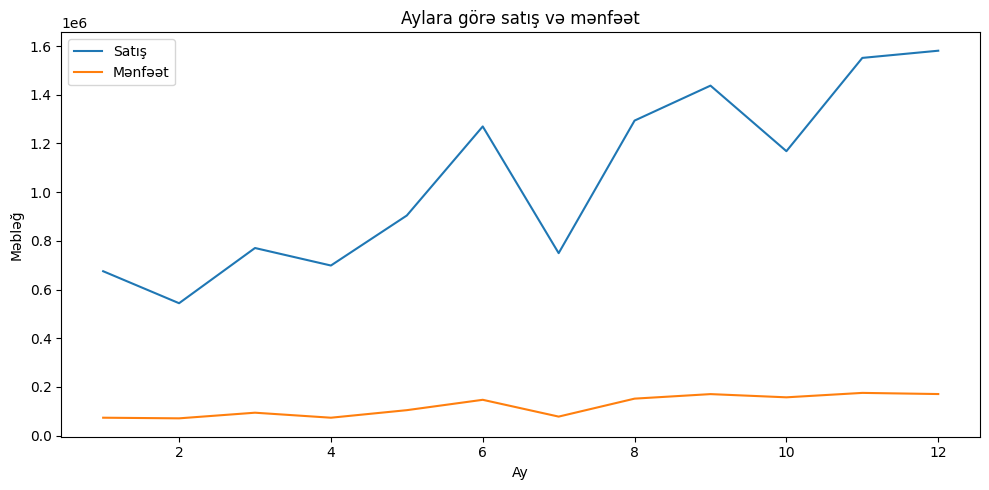

In [31]:
# 1. Aylara görə satış və mənfəət
monthly = df.groupby(df['Order Date'].dt.month)[['Sales', 'Profit']].sum().reset_index()
plt.figure(figsize=(10,5))
sns.lineplot(x='Order Date', y='Sales', data=monthly, label='Satış')
sns.lineplot(x='Order Date', y='Profit', data=monthly, label='Mənfəət')
plt.title('Aylara görə satış və mənfəət')
plt.xlabel('Ay')
plt.ylabel('Məbləğ')
plt.legend()
plt.tight_layout()
plt.show()



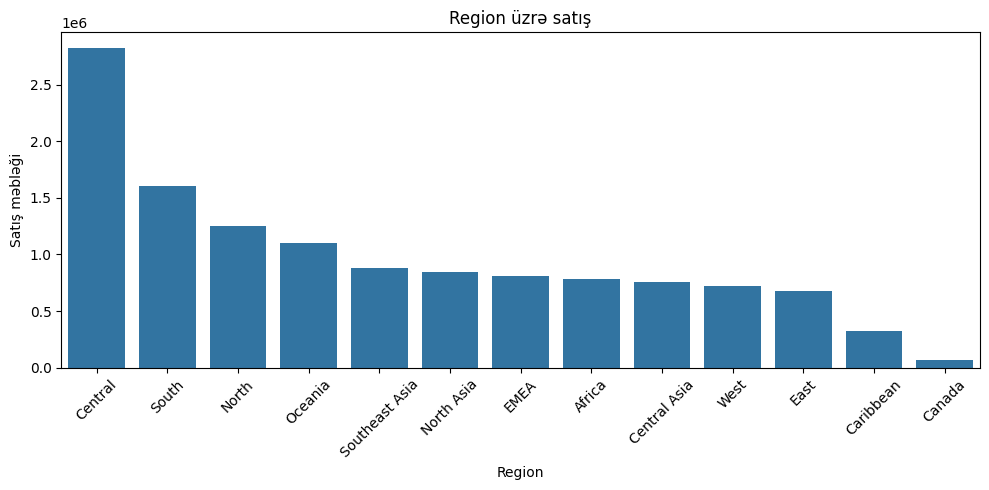

In [32]:
# 2. Region üzrə satış
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title('Region üzrə satış')
plt.xlabel('Region')
plt.ylabel('Satış məbləği')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

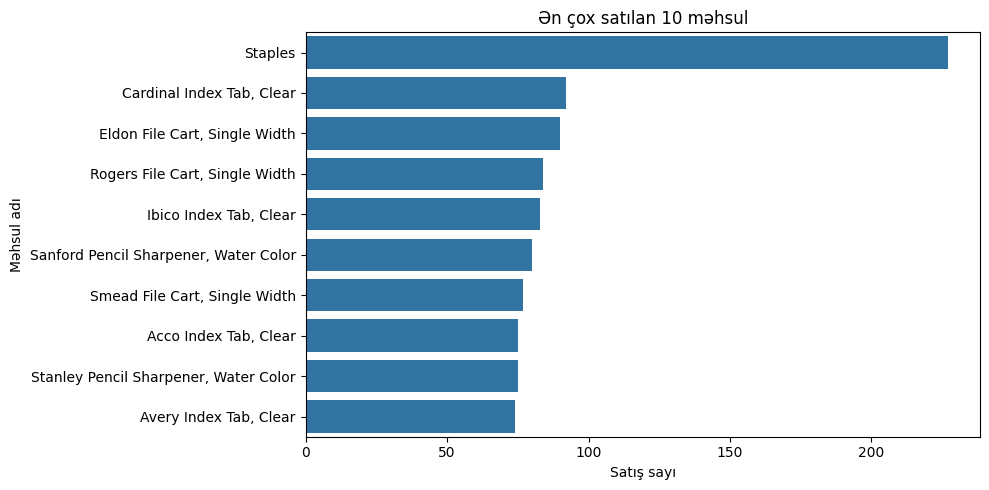

In [33]:
# 4. Ən çox satılan məhsullar
top_products = df['Product Name'].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title('Ən çox satılan 10 məhsul')
plt.xlabel('Satış sayı')
plt.ylabel('Məhsul adı')
plt.tight_layout()
plt.show()

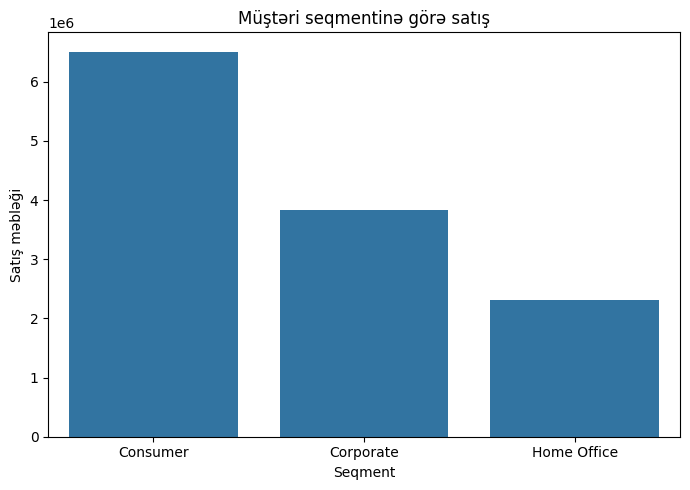

In [34]:
# 5. Müştəri seqmentinə görə satış
segment_sales = df.groupby('Segment')['Sales'].sum()
plt.figure(figsize=(7,5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)
plt.title('Müştəri seqmentinə görə satış')
plt.xlabel('Seqment')
plt.ylabel('Satış məbləği')
plt.tight_layout()
plt.show()

In [35]:
# Göndərilmə sürətini hesablamaq (gün cinsində)
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Prioritet üzrə orta satış, orta mənfəət, orta göndərilmə sürəti
priority_stats = df.groupby('Order Priority').agg({
    'Sales': 'mean',
    'Profit': 'mean',
    'Shipping_Days': 'mean',
    'Order ID': 'count'
}).rename(columns={'Order ID': 'Order Count'}).sort_values(by='Sales', ascending=False)

print("Sifariş prioritetinə görə orta satış, mənfəət və göndərilmə sürəti:")
print(priority_stats)

Sifariş prioritetinə görə orta satış, mənfəət və göndərilmə sürəti:
                Sales  Profit  Shipping_Days  Order Count
Order Priority                                           
Critical       250.82   31.59           1.81         3932
Medium         247.37   29.36           4.52        29433
High           245.63   27.12           3.09        15501
Low            234.25   24.20           6.48         2424


> Sifariş prioritetinə görə aparılan analiz göstərir ki, sifarişin biznes üçün əhəmiyyəti satış və mənfəət göstəricilərinə, eləcə də göndərilmə sürətinə birbaşa təsir edir. Ən yüksək prioritetə malik olan “Critical” kateqoriyasında orta satış və mənfəət dəyərləri ən yüksəkdir (250.82 və 31.59), həmçinin bu sifarişlər ən tez göndərilir (orta göndərilmə müddəti cəmi 1.81 gündür). Bu, şirkətin ən vacib müştərilərə sürətli və gəlirli xidmət göstərdiyini əks etdirir. Ən çox sifariş sayı isə “Medium” prioritetindədir — burada orta satış və mənfəət göstəriciləri bir az azalır (247.37 və 29.36), göndərilmə sürəti isə xeyli uzanır (4.52 gün). “High” prioritetli sifarişlərdə satış və mənfəət daha da aşağıdır və göndərilmə müddəti orta səviyyədədir (3.09 gün). “Low” prioritetli sifarişlər isə ən aşağı satış və mənfəət gətirir, həm də ən gec göndərilir (6.48 gün). Bu nəticələr onu göstərir ki, şirkət ən yüksək prioritetli sifarişlərə daha çox diqqət ayırır, onlardan daha çox gəlir əldə edir və müştəri məmnuniyyətini artırmaq üçün onları daha tez çatdırır. Digər tərəfdən, aşağı prioritetli sifarişlər biznes üçün o qədər də sərfəli deyil və çatdırılma müddəti uzundur. Bu analiz şirkətə sifarişlərin prioritetinə uyğun olaraq xidmət və logistikanı optimallaşdırmaq üçün real imkanlar verir.



In [36]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country',
       'Postal Code', 'Market', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping Cost', 'Order Priority', 'Shipping_Days'],
      dtype='object')

In [37]:
# Ən sadiq və təkrar alış edən müştərilər (ən çox sifariş verənlər)
top_customers = df['Customer ID'].value_counts().head(10)
print("Ən sadiq/təkrar alış edən 10 müştəri:")
print(top_customers)

# Müştəri seqmentasiyası üzrə satış və mənfəət analizi
segment_stats = df.groupby('Segment')[['Sales', 'Profit']].agg(['sum', 'mean', 'count'])
print("\nMüştəri seqmentasiyası üzrə satış və mənfəət:")
print(segment_stats)

Ən sadiq/təkrar alış edən 10 müştəri:
Customer ID
PO-18850    97
BE-11335    94
JG-15805    90
SW-20755    89
MY-18295    85
EM-13960    85
ZC-21910    84
MP-17965    84
CK-12205    83
AF-10870    81
Name: count, dtype: int64

Müştəri seqmentasiyası üzrə satış və mənfəət:
                 Sales                  Profit             
                   sum   mean  count       sum  mean  count
Segment                                                    
Consumer    6507949.42 245.42  26518 749239.78 28.25  26518
Corporate   3824697.52 247.89  15429 441208.33 28.60  15429
Home Office 2309854.97 247.23   9343 277009.18 29.65   9343


>Müştəri analitikasına əsasən, ən sadiq və təkrar alış edən müştərilər retail biznesin davamlı satış və gəlir mənbələrinin formalaşmasında mühüm rol oynayır. Analiz göstərir ki, ən çox alış edən müştəri PO-18850 kodlu müştəridir və o, 97 sifariş vermişdir. Digər aktiv müştərilər də 80-dən çox sifarişlə şirkət üçün sabit və güvənli gəlir təmin edirlər. Bu müştəri qrupu loyallıq proqramları və fərdi kampaniyalar üçün əsas hədəf auditoriya kimi seçilə bilər.

>Müştəri seqmentasiyası üzrə satış və mənfəət göstəricilərinə baxdıqda, “Consumer” seqmenti həm satışın, həm də mənfəətin ən böyük hissəsini təşkil edir. Bu seqmentdə ümumi satış məbləği 6,507,949.42, mənfəət isə 749,239.78-dir. “Corporate” və “Home Office” seqmentləri isə bir qədər aşağı göstəricilərə malikdir, lakin hər üç seqment üçün ortalama satış və mənfəət dəyərləri bir-birinə yaxın səviyyədədir. Bu nəticələr göstərir ki, retail biznesdə “Consumer” seqmenti əsas bazar payına sahibdir və müştəri davranışlarının təhlili, satış strategiyasının düzgün qurulmasında, xüsusilə bu seqmentə yönəldilmiş tədbirlərin effektivliyini artırmaq üçün vacibdir.

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
DEBUG:cmdstanpy:input tempfile: /tmp/tmpe5r9tyfn/kfg4x_xn.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmpe5r9tyfn/cuy8q_vq.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=40993', 'data', 'file=/tmp/tmpe5r9tyfn/kfg4x_xn.json', 'init=/tmp/tmpe5r9tyfn/cuy8q_vq.json', 'output', 'file=/tmp/tmpe5r9tyfn/prophet_modelwnqmb2md/prophet_model-20250819182823.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
18:28:23 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
18:28:23 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
/usr/local/lib/python3.12/dist-packages

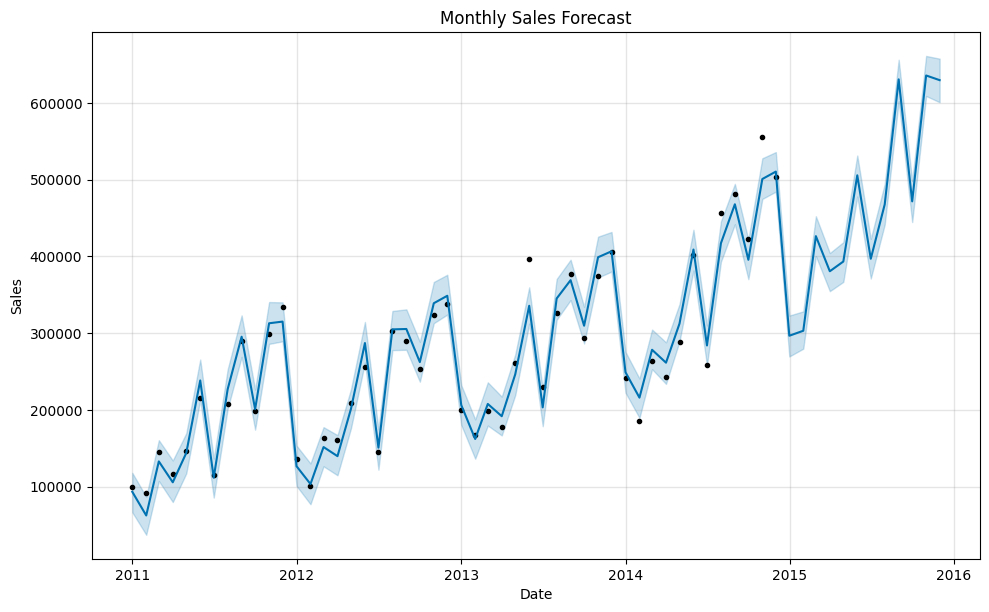

           ds      yhat  yhat_lower  yhat_upper
48 2014-12-31 296583.66   269565.45   322904.40
49 2015-01-31 303056.22   279690.62   328324.07
50 2015-02-28 426372.80   400309.08   452338.33
51 2015-03-31 380605.85   354637.11   404343.36
52 2015-04-30 393275.95   366737.29   418496.23
53 2015-05-31 505607.89   478052.41   531458.56
54 2015-06-30 396874.70   371057.99   422800.08
55 2015-07-31 467753.60   441537.63   494385.35
56 2015-08-31 630655.74   602228.36   656264.30
57 2015-09-30 471666.00   444640.43   498246.82
58 2015-10-31 635698.01   608935.16   661154.81
59 2015-11-30 629622.17   600840.48   657630.83


In [40]:
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum().reset_index()
monthly_sales['Order Date'] = monthly_sales['Order Date'].dt.to_timestamp()
monthly_sales = monthly_sales.rename(columns={'Order Date': 'ds', 'Sales': 'y'})

# Prophet modelinin qurulması və öyrədilməsi
model = Prophet()
model.fit(monthly_sales)

# Gələcək 12 ay üçün proqnoz hazırlanır
future = model.make_future_dataframe(periods=12, freq='M')
forecast = model.predict(future)

# Nəticələrin vizualizasiyası
fig = model.plot(forecast)
plt.title('Monthly Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

# Proqnoz cədvəlini çıxar
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(12))

> Verilən cədvəldə hər ay üçün proqnozlaşdırılmış satış məbləği (“yhat”) və bu proqnozun aşağı-yuxarı sərhədləri (“yhat_lower”, “yhat_upper”) göstərilib.\
Məsələn:

    2014-12-31: Proqnoz satış 296,584, aralığı 269,565–322,904
    2015-01-31: 303,056 (279,691–328,324)
    2015-02-28: 426,373 (400,309–452,338)
    2015-03-31: 380,606 (354,637–404,343)
    2015-04-30: 393,276 (366,737–418,496)
    2015-05-31: 505,608 (478,052–531,459)
    2015-06-30: 396,875 (371,058–422,800)
    2015-07-31: 467,754 (441,538–494,385)
    2015-08-31: 630,656 (602,228–656,264)
    2015-09-30: 471,666 (444,640–498,247)
    2015-10-31: 635,698 (608,935–661,155)
    2015-11-30: 629,622 (600,840–657,631)

> Bu göstəricilər müxtəlif aylarda satışların artım və azalma tendensiyasını göstərir.


> Qrafikdə mavi xətt proqnozlaşdırılmış satışları, mavi kölgə isə proqnozun etibarlılıq intervalını göstərir. Qara nöqtələr isə real satış məlumatlarını əks etdirir.




*       Satışlar zamanla artan tendensiyaya malikdir. 2011-ci ildən 2015-ci ilə qədər satışlarda ardıcıl artım müşahidə olunur.
*       Mövsümi dalğalanmalar var. Hər ilin son aylarında satışlarda kəskin sıçrayışlar müşahidə olunur. Bu, retail biznesdə ilin sonuna doğru alış-veriş aktivliyinin yüksəldiyinə işarədir.
*       2015-ci ilin ortalarından sonra proqnozlar daha yüksək satışları göstərir. Xüsusilə avqust, oktyabr və noyabr aylarında satışların 600,000-dən çox olacağı proqnozlaşdırılır.
*    Proqnoz intervalı (mavi kölgə) daraldıqca modelin güvəni artır. Bu, data və modelin uyğunluğunun yaxşı olduğunu göstərir.








> Proqnozlara əsaslanaraq retail satışların gələcək aylarda artacağı gözlənilir, xüsusilə ilin ikinci yarısında satışların daha yüksək olacağı ehtimal edilir. Mövsümi dalğalanmalar və ilin sonuna doğru satış sıçrayışları biznes strategiyasının planlaşdırılmasında mühüm rol oynayır. Bu proqnozlar stok planlaması, marketinq kampaniyaları və resursların effektiv idarə olunması üçün əsas verir.